<a href="https://colab.research.google.com/github/Harshita180405/Deep-Attentional-ColdStart-Framework/blob/main/Traffic_Sign_Recognition_ViT_GTSRB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Traffic Sign Recognition using Vision Transformer (ViT)
### Case Study 12 — German Traffic Sign Recognition Benchmark (GTSRB)

**Student:** Harshita Rathor  
**Roll Number:** 23FE10ITE00353  
**Programme:** B.Tech Information Technology  
**Institution:** Manipal University Jaipur  

This notebook builds and evaluates a Vision Transformer (ViT) classifier for the 43 GTSRB traffic-sign categories. It also trains a CNN baseline, compares their test metrics, and provides an image-upload prediction demo.

> **Execution note:** Run in Google Colab with a GPU runtime if possible. The notebook does not fabricate results: all metrics and plots are generated after the models are trained. Dataset access is configurable because the official GTSRB downloads and archive layouts may change.

## 1. Objectives

- Load and inspect the German Traffic Sign Recognition Benchmark.
- Preprocess images into a consistent input shape and normalize pixel values.
- Train a patch-based Vision Transformer with multi-head self-attention.
- Train a compact CNN baseline under comparable data conditions.
- Evaluate both models using accuracy, precision, recall, F1-score and a confusion matrix.
- Visualize learning curves and inspect example predictions.
- Discuss limitations, computational cost and possible improvements.

In [1]:
!pip install -q tensorflow scikit-learn pandas numpy matplotlib seaborn pillow

## 2. Dataset

GTSRB is a multi-class traffic-sign image classification benchmark containing **43 classes**. Images vary in size, lighting, viewpoint, and background. The official dataset page is:

- [GTSRB dataset — official benchmark site](https://benchmark.ini.rub.de/gtsrb_dataset.html)

### Dataset setup

Download the training and test archives from the official page and extract them. For the commonly distributed GTSRB format, the training data contains class-wise folders and the test set is accompanied by a CSV annotation file. This notebook supports:
1. A folder named `Train` with subfolders `0` to `42` (or equivalent class folders), and
2. A `Test` folder plus `Test.csv` containing image paths and class labels.

If using Google Colab, upload/extract the archives into `/content/gtsrb/` or change `DATA_ROOT` below.

In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [2]:
import zipfile

with zipfile.ZipFile("archive (2).zip", "r") as zip_ref:
    zip_ref.extractall("/content/gtsrb")

In [4]:
from pathlib import Path

DATA_ROOT = Path("/content/gtsrb")

print("Dataset path:", DATA_ROOT)
print("Folder exists:", DATA_ROOT.exists())

Dataset path: /content/gtsrb
Folder exists: True


In [5]:
DATA_ROOT = Path("/content/gtsrb")

In [10]:
from pathlib import Path
import os, glob, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
from pathlib import Path

DATA_ROOT = Path("/content/gtsrb")
IMG_SIZE = 48
NUM_CLASSES = 43
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Dataset loading and preprocessing

The loader first tries to read the standard class-folder training layout. It creates a stratified validation split from the training data. Test annotations are read from `Test.csv` when available. If the test archive is unavailable, a held-out stratified split is used and clearly labelled as a validation proxy; obtain the official test set for a formal final evaluation.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_recall_fscore_support

def find_image_files(folder):
    exts = ("*.png", "*.jpg", "*.jpeg", "*.ppm", "*.bmp")
    files = []
    for ext in exts:
        files.extend(folder.rglob(ext))
    return sorted(files)

def load_class_folder(folder):
    paths, labels = [], []
    class_dirs = [p for p in folder.iterdir() if p.is_dir()]
    for d in sorted(class_dirs, key=lambda x: int(x.name) if x.name.isdigit() else x.name):
        try:
            label = int(d.name)
        except ValueError:
            continue
        if 0 <= label < NUM_CLASSES:
            for p in find_image_files(d):
                paths.append(str(p))
                labels.append(label)
    if not paths:
        raise FileNotFoundError(f"No class-folder images found under {folder}")
    return np.asarray(paths), np.asarray(labels, dtype=np.int64)

def resolve_train_dir(root):
    candidates = [root/"Train", root/"train", root/"GTSRB"/"Final_Training"/"Images",
                  root/"Final_Training"/"Images", root]
    for candidate in candidates:
        if candidate.exists():
            try:
                p, y = load_class_folder(candidate)
                if len(p): return candidate, p, y
            except Exception:
                pass
    raise FileNotFoundError(
        f"Could not find class-wise training folders. Expected {root}/Train/0 ... {root}/Train/42. "
        "Extract the official training archive and update DATA_ROOT."
    )

train_dir, all_train_paths, all_train_labels = resolve_train_dir(DATA_ROOT)
print("Training directory:", train_dir)
print("Training images:", len(all_train_paths))
print("Classes found:", len(np.unique(all_train_labels)))

train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_train_paths, all_train_labels, test_size=0.15, random_state=SEED,
    stratify=all_train_labels
)

def load_test_csv(root):
    csv_candidates = list(root.rglob("Test.csv"))
    if not csv_candidates:
        return None, None
    csv_path = csv_candidates[0]
    df = pd.read_csv(csv_path)
    path_col = next((c for c in df.columns if c.lower() in ["path", "filename", "image"]), None)
    label_col = next((c for c in df.columns if c.lower() in ["classid", "class_id", "label"]), None)
    if path_col is None or label_col is None:
        print("Test.csv found but expected path/label columns were not detected:", df.columns.tolist())
        return None, None
    base = csv_path.parent
    paths = []
    for rel in df[path_col].astype(str):
        p = Path(rel)
        paths.append(str(p if p.is_absolute() else base / p))
    labels = df[label_col].astype(int).to_numpy()
    keep = [i for i, p in enumerate(paths) if Path(p).exists()]
    return np.asarray(paths)[keep], labels[keep]

test_paths, test_labels = load_test_csv(DATA_ROOT)
if test_paths is None or len(test_paths) == 0:
    print("WARNING: Official Test.csv/test images not found. Creating a held-out test split from training data.")
    train_paths, test_paths, train_labels, test_labels = train_test_split(
        train_paths, train_labels, test_size=0.15, random_state=SEED + 1,
        stratify=train_labels
    )
    TEST_SET_NOTE = "Held-out split from training archive (not official benchmark test set)"
else:
    TEST_SET_NOTE = "Official GTSRB test annotations"
print("Train / validation / test:", len(train_paths), len(val_paths), len(test_paths))
print("Test protocol:", TEST_SET_NOTE)

Training directory: /content/gtsrb/Train
Training images: 39209
Classes found: 43
Train / validation / test: 33327 5882 12630
Test protocol: Official GTSRB test annotations


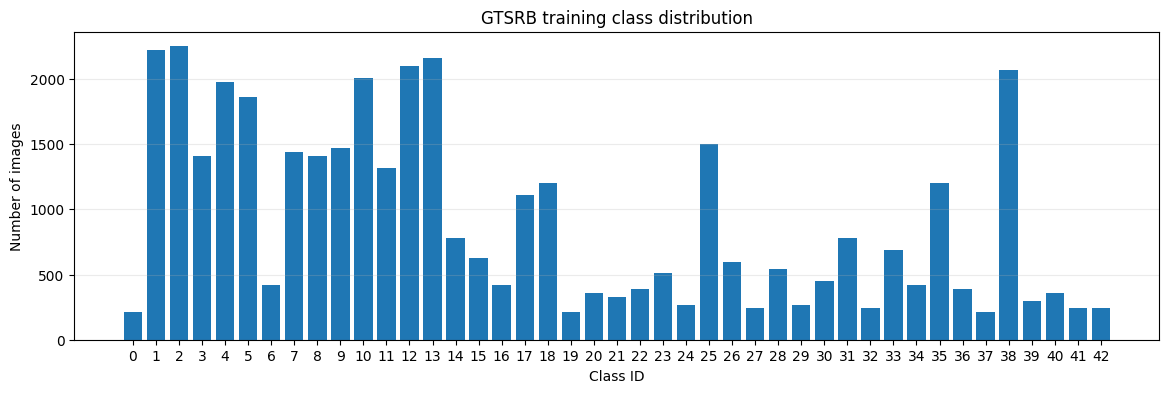

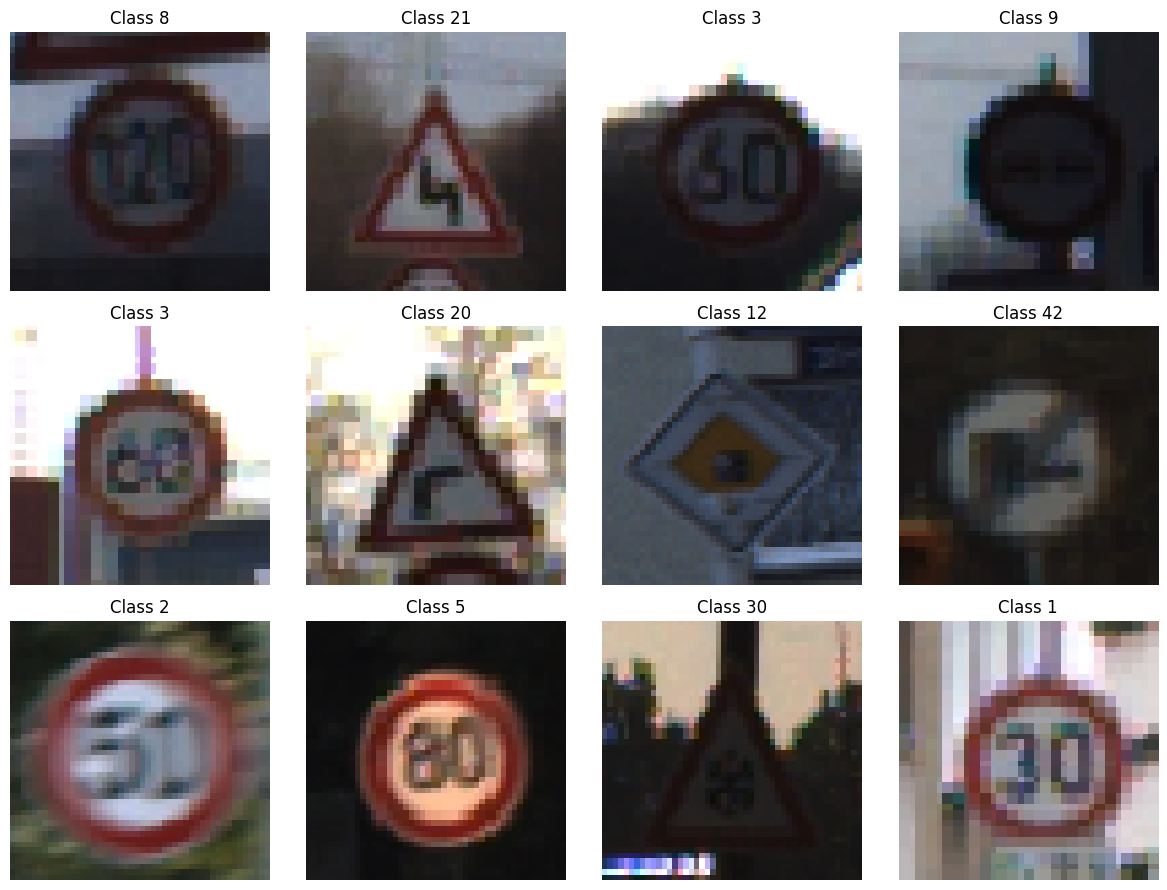

In [12]:
counts = pd.Series(all_train_labels).value_counts().sort_index()
plt.figure(figsize=(14, 4))
plt.bar(counts.index, counts.values)
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.title("GTSRB training class distribution")
plt.xticks(range(NUM_CLASSES))
plt.grid(axis="y", alpha=0.25)
plt.show()

def show_samples(paths, labels, n=12):
    idx = np.random.choice(len(paths), min(n, len(paths)), replace=False)
    cols = 4
    rows = math.ceil(len(idx)/cols)
    plt.figure(figsize=(12, 3*rows))
    for j, i in enumerate(idx, 1):
        img = tf.keras.utils.load_img(paths[i], target_size=(IMG_SIZE, IMG_SIZE))
        plt.subplot(rows, cols, j)
        plt.imshow(img)
        plt.title(f"Class {labels[i]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(train_paths, train_labels)

## 4. Input pipeline and augmentation

Images are resized to 48×48 RGB and normalized to `[0, 1]`. Mild augmentation helps the models generalize to changes in orientation, scale and illumination. Horizontal flips are intentionally not used because flipping a traffic sign can change its meaning.

In [13]:
augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.08, 0.08),
    tf.keras.layers.RandomContrast(0.15),
], name="training_augmentation")

def decode_resize(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.int32)

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(min(len(paths), 20000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

for xb, yb in train_ds.take(1):
    print("Batch images:", xb.shape, "Batch labels:", yb.shape)

Batch images: (64, 48, 48, 3) Batch labels: (64,)


## 5. Vision Transformer architecture

The image is divided into non-overlapping patches. Each patch is projected into an embedding vector, positional embeddings preserve spatial order, and Transformer encoder blocks learn relationships between patches using multi-head self-attention. A classification token is passed to a dense classification head.

**Chosen configuration:** 48×48 input, 6×6 patches (64 patches), embedding dimension 128, 4 attention heads, 4 Transformer blocks, MLP dimension 256, and 43 output classes. This compact ViT is suitable for a student project and can be scaled up if GPU resources allow.

In [14]:
from tensorflow.keras import layers, Model

class Patches(layers.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size
    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID"
        )
        patch_dims = patches.shape[-1]
        return tf.reshape(patches, [batch_size, -1, patch_dims])

class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.projection = layers.Dense(projection_dim)
        self.position_embedding = layers.Embedding(input_dim=num_patches, output_dim=projection_dim)
        self.num_patches = num_patches
    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        return self.projection(patch) + self.position_embedding(positions)

def transformer_block(x, projection_dim, num_heads, mlp_dim, dropout=0.1):
    x1 = layers.LayerNormalization(epsilon=1e-6)(x)
    attention = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=projection_dim // num_heads,
        dropout=dropout
    )(x1, x1)
    x2 = layers.Add()([x, attention])
    x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
    mlp = layers.Dense(mlp_dim, activation=tf.nn.gelu)(x3)
    mlp = layers.Dropout(dropout)(mlp)
    mlp = layers.Dense(projection_dim)(mlp)
    mlp = layers.Dropout(dropout)(mlp)
    return layers.Add()([x2, mlp])

def build_vit():
    patch_size = 6
    num_patches = (IMG_SIZE // patch_size) ** 2
    projection_dim = 128
    num_heads = 4
    mlp_dim = 256
    num_transformer_blocks = 4

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    patches = Patches(patch_size)(inputs)
    x = PatchEncoder(num_patches, projection_dim)(patches)
    for _ in range(num_transformer_blocks):
        x = transformer_block(x, projection_dim, num_heads, mlp_dim)
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="gelu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return Model(inputs, outputs, name="GTSRB_Vision_Transformer")

vit_model = build_vit()
vit_model.summary()

Model: "GTSRB_Vision_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 48, 48, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, None, 108) │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 64, 128)   │     22,144 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 128)   │        256 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 128)   │          0 │ patch_encoder[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64, 256)   │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 256)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64, 128)   │     32,896 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 128)   │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 128)   │          0 │ add[0][0],        │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 128)   │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 128)   │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 128)   │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64, 256)   │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64, 256)   │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64, 128)   │     32,896 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 574,379 (2.19 MB)

 Trainable params: 574,379 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

## 6. CNN baseline

A compact convolutional neural network is trained on the same resized images and split. It serves as a conventional computer-vision baseline for comparison with the ViT.

In [15]:
def build_cnn():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = inputs
    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.20)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return Model(inputs, outputs, name="GTSRB_CNN_Baseline")

cnn_model = build_cnn()
cnn_model.summary()

Model: "GTSRB_CNN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 310,411 (1.18 MB)

 Trainable params: 309,515 (1.18 MB)

 Non-trainable params: 896 (3.50 KB)

## 7. Training configuration

The models use Adam, sparse categorical cross-entropy and early stopping. Adjust epochs or batch size based on available compute. A GPU is recommended. The best validation checkpoint is restored automatically.

In [16]:
EPOCHS = 20
LEARNING_RATE = 1e-3

def compile_model(model):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

def train_model(model, model_name):
    compile_model(model)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=5, mode="max",
            restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2,
            min_lr=1e-6, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            f"{model_name}_best.keras", monitor="val_accuracy",
            save_best_only=True, mode="max", verbose=1
        )
    ]
    return model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS,
        callbacks=callbacks, verbose=1
    )

vit_history = train_model(vit_model, "gtsrb_vit")

Epoch 1/20
521/521 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.0979 - loss: 3.3956
Epoch 1: val_accuracy improved from None to 0.23172, saving model to gtsrb_vit_best.keras

Epoch 1: finished saving model to gtsrb_vit_best.keras
521/521 ━━━━━━━━━━━━━━━━━━━━ 119s 173ms/step - accuracy: 0.1408 - loss: 3.1007 - val_accuracy: 0.2317 - val_loss: 2.4249 - learning_rate: 0.0010
Epoch 2/20
521/521 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.2394 - loss: 2.4874
Epoch 2: val_accuracy improved from 0.23172 to 0.39884, saving model to gtsrb_vit_best.keras

Epoch 2: finished saving model to gtsrb_vit_best.keras
521/521 ━━━━━━━━━━━━━━━━━━━━ 68s 131ms/step - accuracy: 0.2802 - loss: 2.3322 - val_accuracy: 0.3988 - val_loss: 1.7966 - learning_rate: 0.0010
Epoch 3/20
521/521 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.3858 - loss: 1.9112
Epoch 3: val_accuracy improved from 0.39884 to 0.47178, saving model to gtsrb_vit_best.keras

Epoch 3: finished saving model to gtsrb_vit_best.keras
521

In [17]:
cnn_history = train_model(cnn_model, "gtsrb_cnn")

Epoch 1/20
521/521 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.1815 - loss: 3.0211
Epoch 1: val_accuracy improved from None to 0.28766, saving model to gtsrb_cnn_best.keras

Epoch 1: finished saving model to gtsrb_cnn_best.keras
521/521 ━━━━━━━━━━━━━━━━━━━━ 113s 178ms/step - accuracy: 0.2717 - loss: 2.5589 - val_accuracy: 0.2877 - val_loss: 2.4323 - learning_rate: 0.0010
Epoch 2/20
521/521 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.5371 - loss: 1.4458
Epoch 2: val_accuracy improved from 0.28766 to 0.69041, saving model to gtsrb_cnn_best.keras

Epoch 2: finished saving model to gtsrb_cnn_best.keras
521/521 ━━━━━━━━━━━━━━━━━━━━ 69s 131ms/step - accuracy: 0.6133 - loss: 1.2020 - val_accuracy: 0.6904 - val_loss: 0.9482 - learning_rate: 0.0010
Epoch 3/20
521/521 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.7980 - loss: 0.6328
Epoch 3: val_accuracy improved from 0.69041 to 0.90326, saving model to gtsrb_cnn_best.keras

Epoch 3: finished saving model to gtsrb_cnn_best.keras
521

## 8. Training curves

The following plots compare training and validation loss and accuracy. A widening gap between training and validation curves can indicate overfitting.

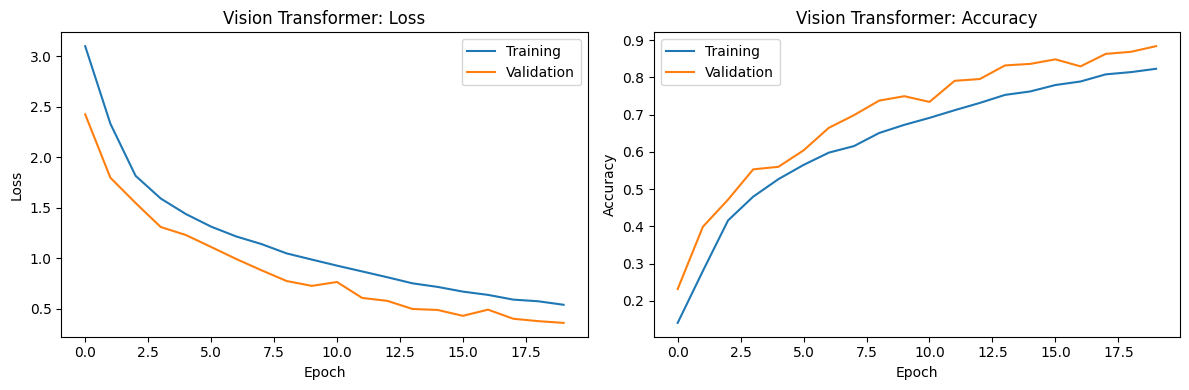

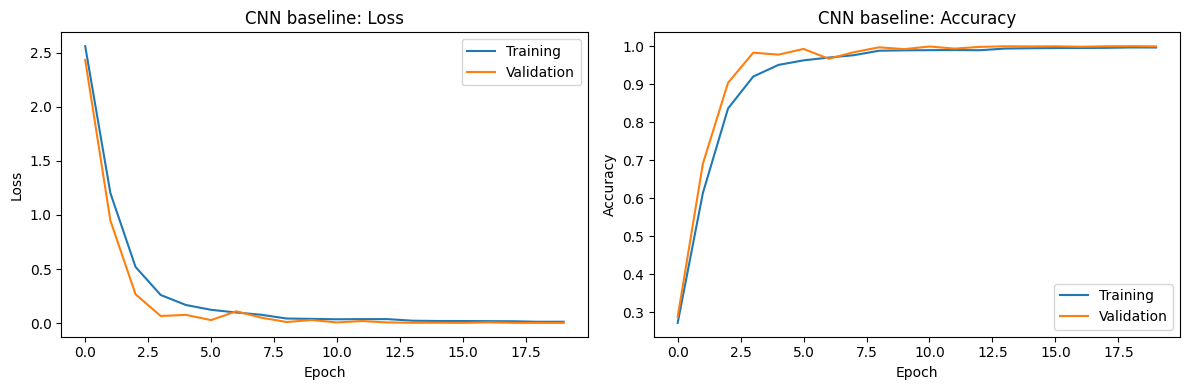

In [18]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist["loss"], label="Training")
    axes[0].plot(hist["val_loss"], label="Validation")
    axes[0].set_title(f"{title}: Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[1].plot(hist["accuracy"], label="Training")
    axes[1].plot(hist["val_accuracy"], label="Validation")
    axes[1].set_title(f"{title}: Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(vit_history, "Vision Transformer")
plot_history(cnn_history, "CNN baseline")

## 9. Test evaluation

Report weighted precision, recall and F1-score because class frequencies may be imbalanced. The confusion matrix provides class-wise error patterns. Use the official test set for benchmark reporting; if the fallback split was used, disclose that in the report.

In [19]:
def collect_predictions(model, dataset):
    y_true, y_prob = [], []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        y_true.extend(labels.numpy().tolist())
        y_prob.extend(probs.tolist())
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    return y_true, np.argmax(y_prob, axis=1), y_prob

def evaluate_model(model, dataset, model_name):
    y_true, y_pred, y_prob = collect_predictions(model, dataset)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Weighted F1-score": f1
    }
    print(f"\n{model_name} classification report")
    print(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                zero_division=0, digits=4))
    return results, y_true, y_pred, y_prob

vit_results, y_true_vit, y_pred_vit, y_prob_vit = evaluate_model(vit_model, test_ds, "ViT")
cnn_results, y_true_cnn, y_pred_cnn, y_prob_cnn = evaluate_model(cnn_model, test_ds, "CNN")

comparison = pd.DataFrame([vit_results, cnn_results])
display(comparison.style.format({c: "{:.4f}" for c in comparison.columns if c != "Model"}))


ViT classification report
              precision    recall  f1-score   support

           0     0.5263    0.1667    0.2532        60
           1     0.7180    0.7250    0.7215       720
           2     0.5274    0.7067    0.6040       750
           3     0.6897    0.6422    0.6651       450
           4     0.7709    0.8818    0.8226       660
           5     0.5416    0.5270    0.5342       630
           6     0.9398    0.5200    0.6695       150
           7     0.7347    0.6156    0.6699       450
           8     0.7980    0.5267    0.6345       450
           9     0.9374    0.9042    0.9205       480
          10     0.9770    0.9667    0.9718       660
          11     0.9818    0.7690    0.8625       420
          12     1.0000    0.8928    0.9433       690
          13     0.9066    0.9972    0.9497       720
          14     0.9097    0.9704    0.9391       270
          15     0.9946    0.8810    0.9343       210
          16     1.0000    0.9733    0.9865       150


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-score
0,ViT,0.7728,0.7883,0.7728,0.7716
1,CNN,0.9803,0.9813,0.9803,0.9800


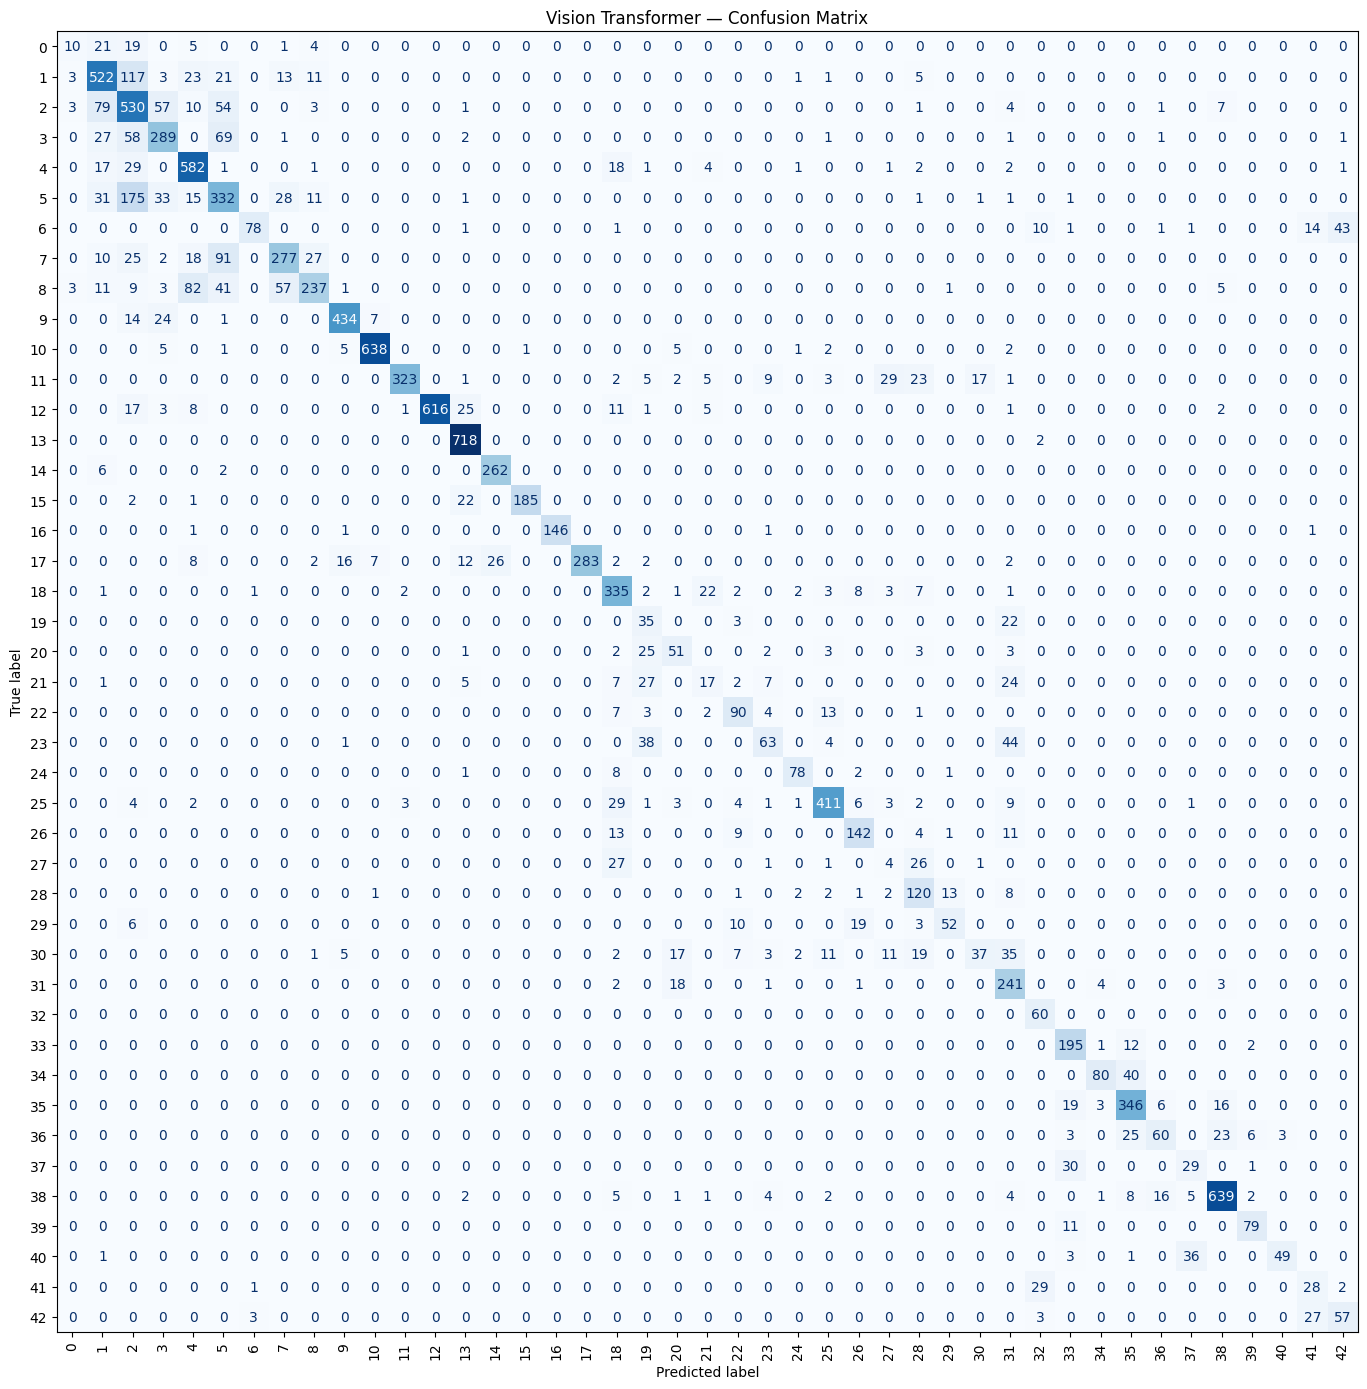

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(
    y_true_vit, y_pred_vit, labels=np.arange(NUM_CLASSES),
    display_labels=np.arange(NUM_CLASSES), cmap="Blues",
    xticks_rotation="vertical", colorbar=False, ax=ax
)
ax.set_title("Vision Transformer — Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. Inspect sample predictions

This cell displays test images with the true and predicted class IDs. Incorrect predictions are especially useful for error analysis.

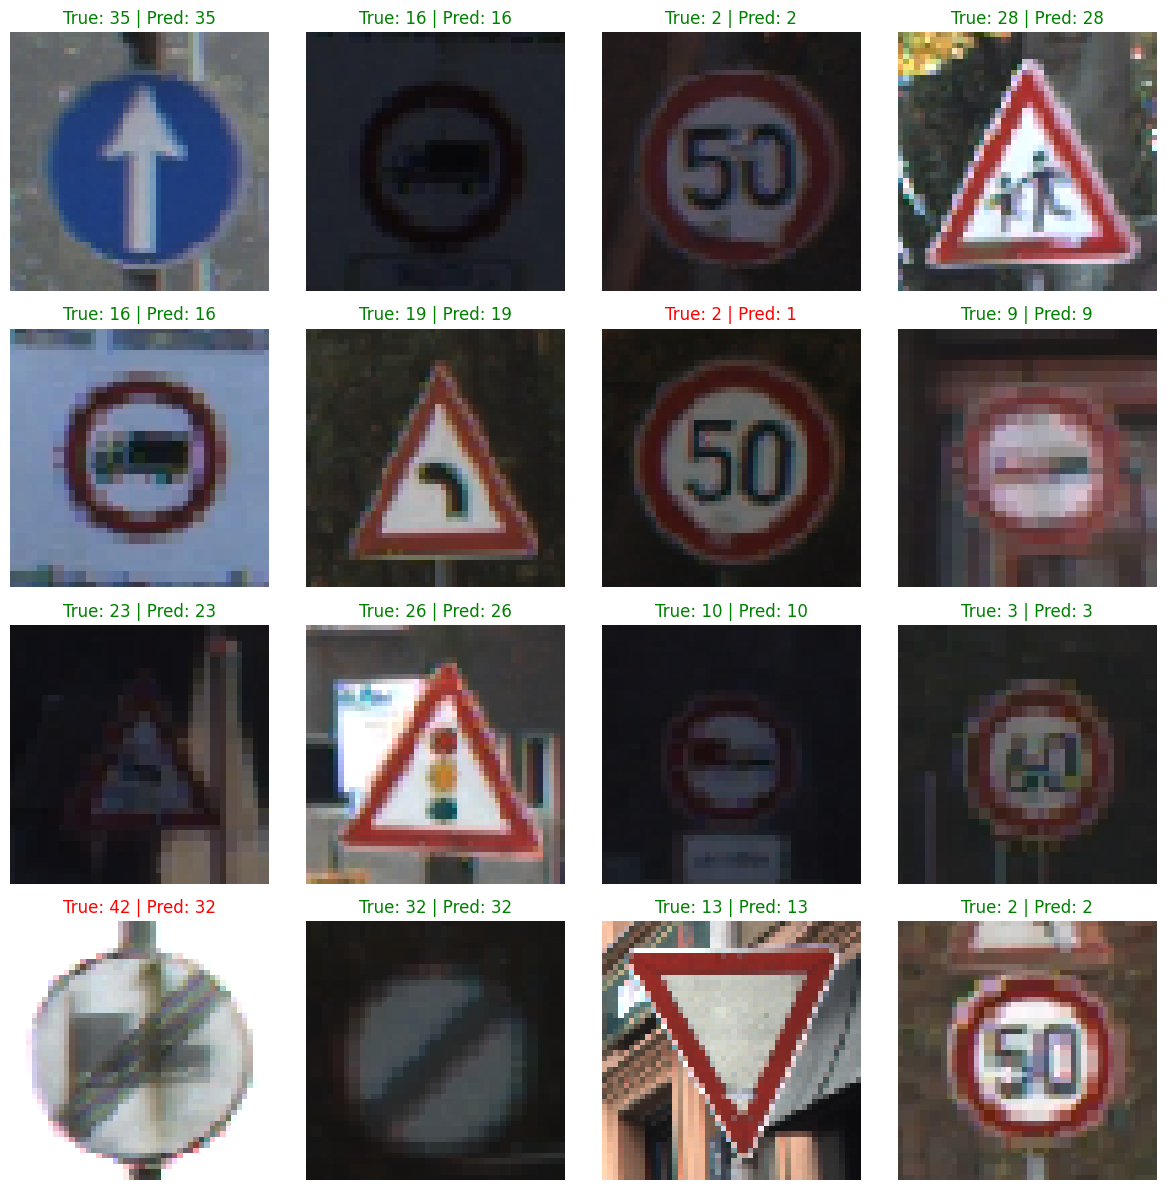

In [21]:
def display_predictions(paths, labels, model, n=16):
    idx = np.random.choice(len(paths), min(n, len(paths)), replace=False)
    cols = 4
    rows = math.ceil(len(idx)/cols)
    plt.figure(figsize=(12, 3*rows))
    for j, i in enumerate(idx, 1):
        img = tf.keras.utils.load_img(paths[i], target_size=(IMG_SIZE, IMG_SIZE))
        arr = tf.keras.utils.img_to_array(img) / 255.0
        pred = int(np.argmax(model.predict(arr[None, ...], verbose=0), axis=1)[0])
        plt.subplot(rows, cols, j)
        plt.imshow(img)
        color = "green" if pred == int(labels[i]) else "red"
        plt.title(f"True: {labels[i]} | Pred: {pred}", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

display_predictions(test_paths, test_labels, vit_model)

## 11. Single-image prediction demo

Upload an image of a traffic sign, or set `IMAGE_PATH` to a local image. The model returns the predicted class ID and confidence. For a polished user-facing interface, this model can be wrapped in Streamlit.

In [23]:
def predict_traffic_sign(image_path, model=vit_model):
    image = tf.keras.utils.load_img(image_path, target_size=(IMG_SIZE, IMG_SIZE))
    array = tf.keras.utils.img_to_array(image).astype("float32") / 255.0
    probabilities = model.predict(array[None, ...], verbose=0)[0]
    class_id = int(np.argmax(probabilities))
    confidence = float(probabilities[class_id])
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Predicted class: {class_id} | Confidence: {confidence:.2%}")
    plt.show()
    return class_id, confidence, probabilities

## 12. Save models and results

The trained Keras models and comparison metrics are saved to the current working directory so they can be reused in a separate demo or included with the submission.

In [24]:
vit_model.save("gtsrb_vit_final.keras")
cnn_model.save("gtsrb_cnn_final.keras")
comparison.to_csv("model_comparison.csv", index=False)

print("Saved: gtsrb_vit_final.keras")
print("Saved: gtsrb_cnn_final.keras")
print("Saved: model_comparison.csv")

Saved: gtsrb_vit_final.keras
Saved: gtsrb_cnn_final.keras
Saved: model_comparison.csv


## 13. Results interpretation and discussion

Complete this section after running the notebook. Do not insert assumed or illustrative values as actual results.

Discuss:
- Which model achieved higher test accuracy and weighted F1-score?
- Did validation performance track training performance, or was there overfitting?
- Which classes show the most confusion in the ViT confusion matrix?
- Did the ViT require more training time or memory than the CNN?
- Were errors associated with small, blurry, partially occluded, or visually similar signs?

### Results table

The notebook generates `comparison` automatically. Copy its actual values into the final report.

| Model | Test accuracy | Weighted precision | Weighted recall | Weighted F1 |
|---|---:|---:|---:|---:|
| Vision Transformer | Run notebook | Run notebook | Run notebook | Run notebook |
| CNN baseline | Run notebook | Run notebook | Run notebook | Run notebook |

## 14. Limitations

1. **Input resolution:** Resizing every image to 48×48 may remove fine visual details from small signs.
2. **Data imbalance:** Some traffic-sign classes have fewer examples, which can reduce minority-class performance.
3. **Domain shift:** Performance may decrease on images captured in different countries, weather, cameras, or road conditions.
4. **Compute requirements:** Self-attention has higher memory and compute requirements as the number of image patches increases.
5. **No real-time deployment guarantee:** This notebook demonstrates image classification, not a complete real-time vehicle perception system.
6. **Dataset split:** If the official test annotations are unavailable, the fallback test split is not directly comparable with published benchmark results.

## 15. Conclusion

This project implements a Vision Transformer for 43-class traffic sign recognition using GTSRB and compares it with a CNN baseline. The ViT converts images into patch embeddings and uses self-attention to model relationships between image regions. The CNN provides a conventional local-feature-learning baseline. Final conclusions must be based on the measured test metrics and observed error patterns generated by the executed notebook.

### Future improvements
- Use a pretrained ViT backbone and fine-tune it on GTSRB.
- Experiment with higher input resolution and stronger, sign-safe augmentation.
- Use class-weighted loss or balanced sampling.
- Perform repeated runs with multiple random seeds.
- Export the best model to TensorFlow Lite for edge-device inference.

## 16. References

1. German Traffic Sign Recognition Benchmark (GTSRB), official benchmark website: https://benchmark.ini.rub.de/gtsrb_dataset.html
2. Dosovitskiy, A. et al. (2021). *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*. ICLR.
3. Vaswani, A. et al. (2017). *Attention Is All You Need*. NeurIPS.
4. TensorFlow documentation: https://www.tensorflow.org/
5. Scikit-learn documentation: https://scikit-learn.org/